In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
filepath = '/content/drive/MyDrive/Colab Notebooks/dataset/quickkart_customers.csv'

In [ ]:
df = pd.read_csv(filepath)

df.head(10)

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0
5,C0800,24.0,Male,Kozhikode,Gold,Credit Card,32100.0,14.0,480.0,6344.0
6,C1440,29.0,Male,Kollam,Silver,Debit Card,38000.0,16.0,260.0,3890.0
7,C1422,42.0,Female,Kollam,Gold,Debit Card,40900.0,18.0,1302.0,25298.0
8,C1200,18.0,Female,Kochi,Silver,Cash on Delivery,66400.0,8.0,440.0,3643.0
9,C0516,43.0,Male,kochi,Basic,Debit Card,33300.0,8.0,482.0,3733.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Customer_ID       1500 non-null   object 
 1   Age               1419 non-null   float64
 2   Gender            1449 non-null   object 
 3   City              1434 non-null   object 
 4   Membership        1500 non-null   object 
 5   Payment_Mode      1405 non-null   object 
 6   Monthly_Income    1346 non-null   float64
 7   Orders_Last_Year  1500 non-null   float64
 8   Avg_Order_Value   1376 non-null   float64
 9   Total_Spent       1500 non-null   float64
dtypes: float64(5), object(5)
memory usage: 117.3+ KB


In [ ]:
df.describe()

,Age,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
count,1419.000000,1346.000000,1500.000000,1376.000000,1500.000000
mean,34.248062,43418.424963,8.986667,817.260901,5723.821333
std,10.554268,62967.813712,15.567661,1805.319096,6497.750986
min,-3.000000,5500.000000,1.000000,81.000000,157.000000
25%,27.000000,24100.000000,4.000000,401.000000,1937.750000
50%,34.000000,33600.000000,7.000000,579.500000,3820.500000
75%,41.000000,47300.000000,11.000000,868.250000,7280.250000
max,150.000000,900000.000000,310.000000,35000.000000,85073.000000


In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Age,81
Gender,51
City,66
Membership,0
Payment_Mode,95
Monthly_Income,154
Orders_Last_Year,0
Avg_Order_Value,124
Total_Spent,0


In [ ]:
num_Total_Spents = df.select_dtypes(include=['number'])
cat_Total_Spents = df.select_dtypes(include=['number'])
num_Total_Spents
cat_Total_Spents

,Age,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,29.0,55900.0,6.0,523.0,3143.0
1,36.0,47900.0,21.0,855.0,16395.0
2,18.0,32600.0,2.0,491.0,1007.0
3,32.0,32900.0,12.0,1776.0,22554.0
4,34.0,81000.0,10.0,426.0,3915.0
...,...,...,...,...,...
1495,18.0,59300.0,9.0,488.0,4333.0
1496,36.0,37900.0,2.0,268.0,559.0
1497,24.0,45200.0,11.0,395.0,4213.0
1498,26.0,23300.0,4.0,626.0,2493.0


In [ ]:
df['Age'].fillna(df['Age'].median(), inplace=True)
df['Monthly_Income'].fillna(df['Monthly_Income'].median(), inplace=True)
df['Orders_Last_Year'].fillna(df['Orders_Last_Year'].median(), inplace=True)
df['Avg_Order_Value'].fillna(df['Avg_Order_Value'].median(), inplace=True)
df['Total_Spent'].fillna(df['Total_Spent'].median(), inplace=True)

# category
df['Gender']=df['Gender'].fillna(df['Gender'].mode()[0])
df['City']= df['City'].fillna(df['City'].mode()[0])
df['Payment_Mode']= df['Payment_Mode'].fillna(df['Payment_Mode'].mode()[0])

/tmp/ipykernel_826/989645895.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)
/tmp/ipykernel_826/989645895.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try us

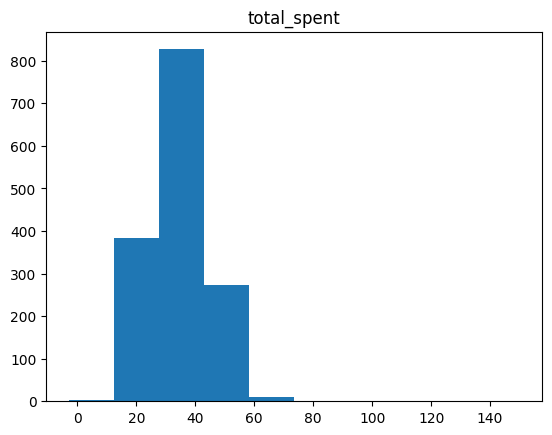

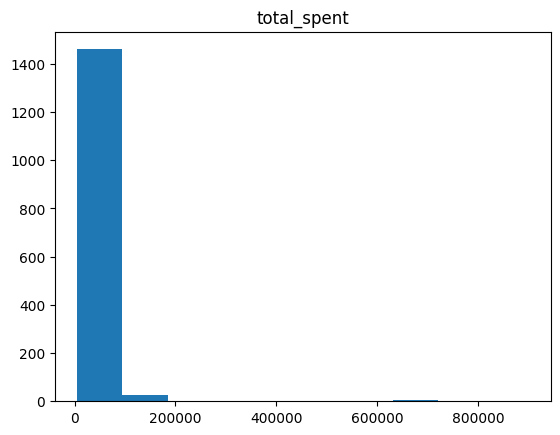

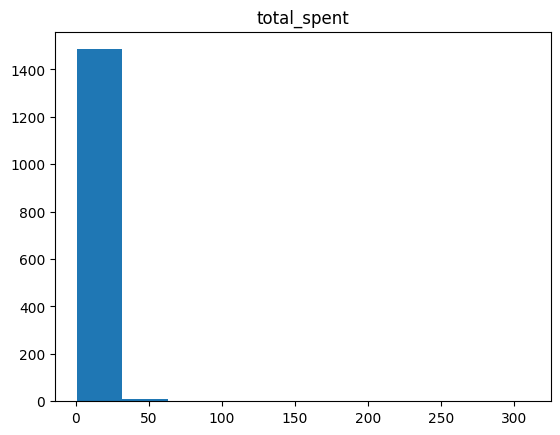

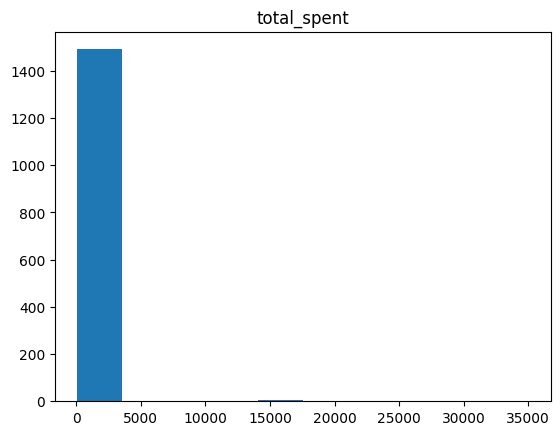

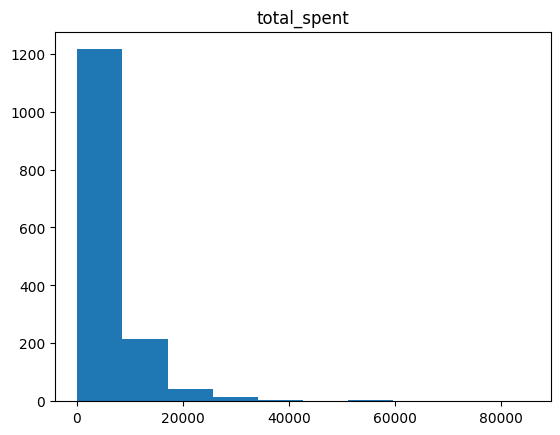

In [ ]:
for spent in num_Total_Spents:
  plt.hist(df[spent])
  plt.title('total_spent')
  plt.show()

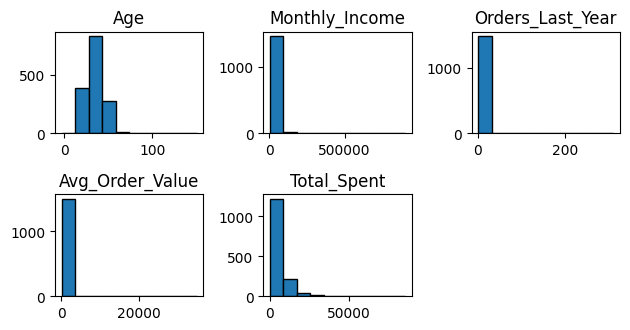

In [ ]:
for  i, spent in enumerate(num_Total_Spents, 1):
  plt.subplot(3, 3, i)
  plt.hist(df[spent], edgecolor='black')
  plt.title(spent)
plt.tight_layout()
plt.show()


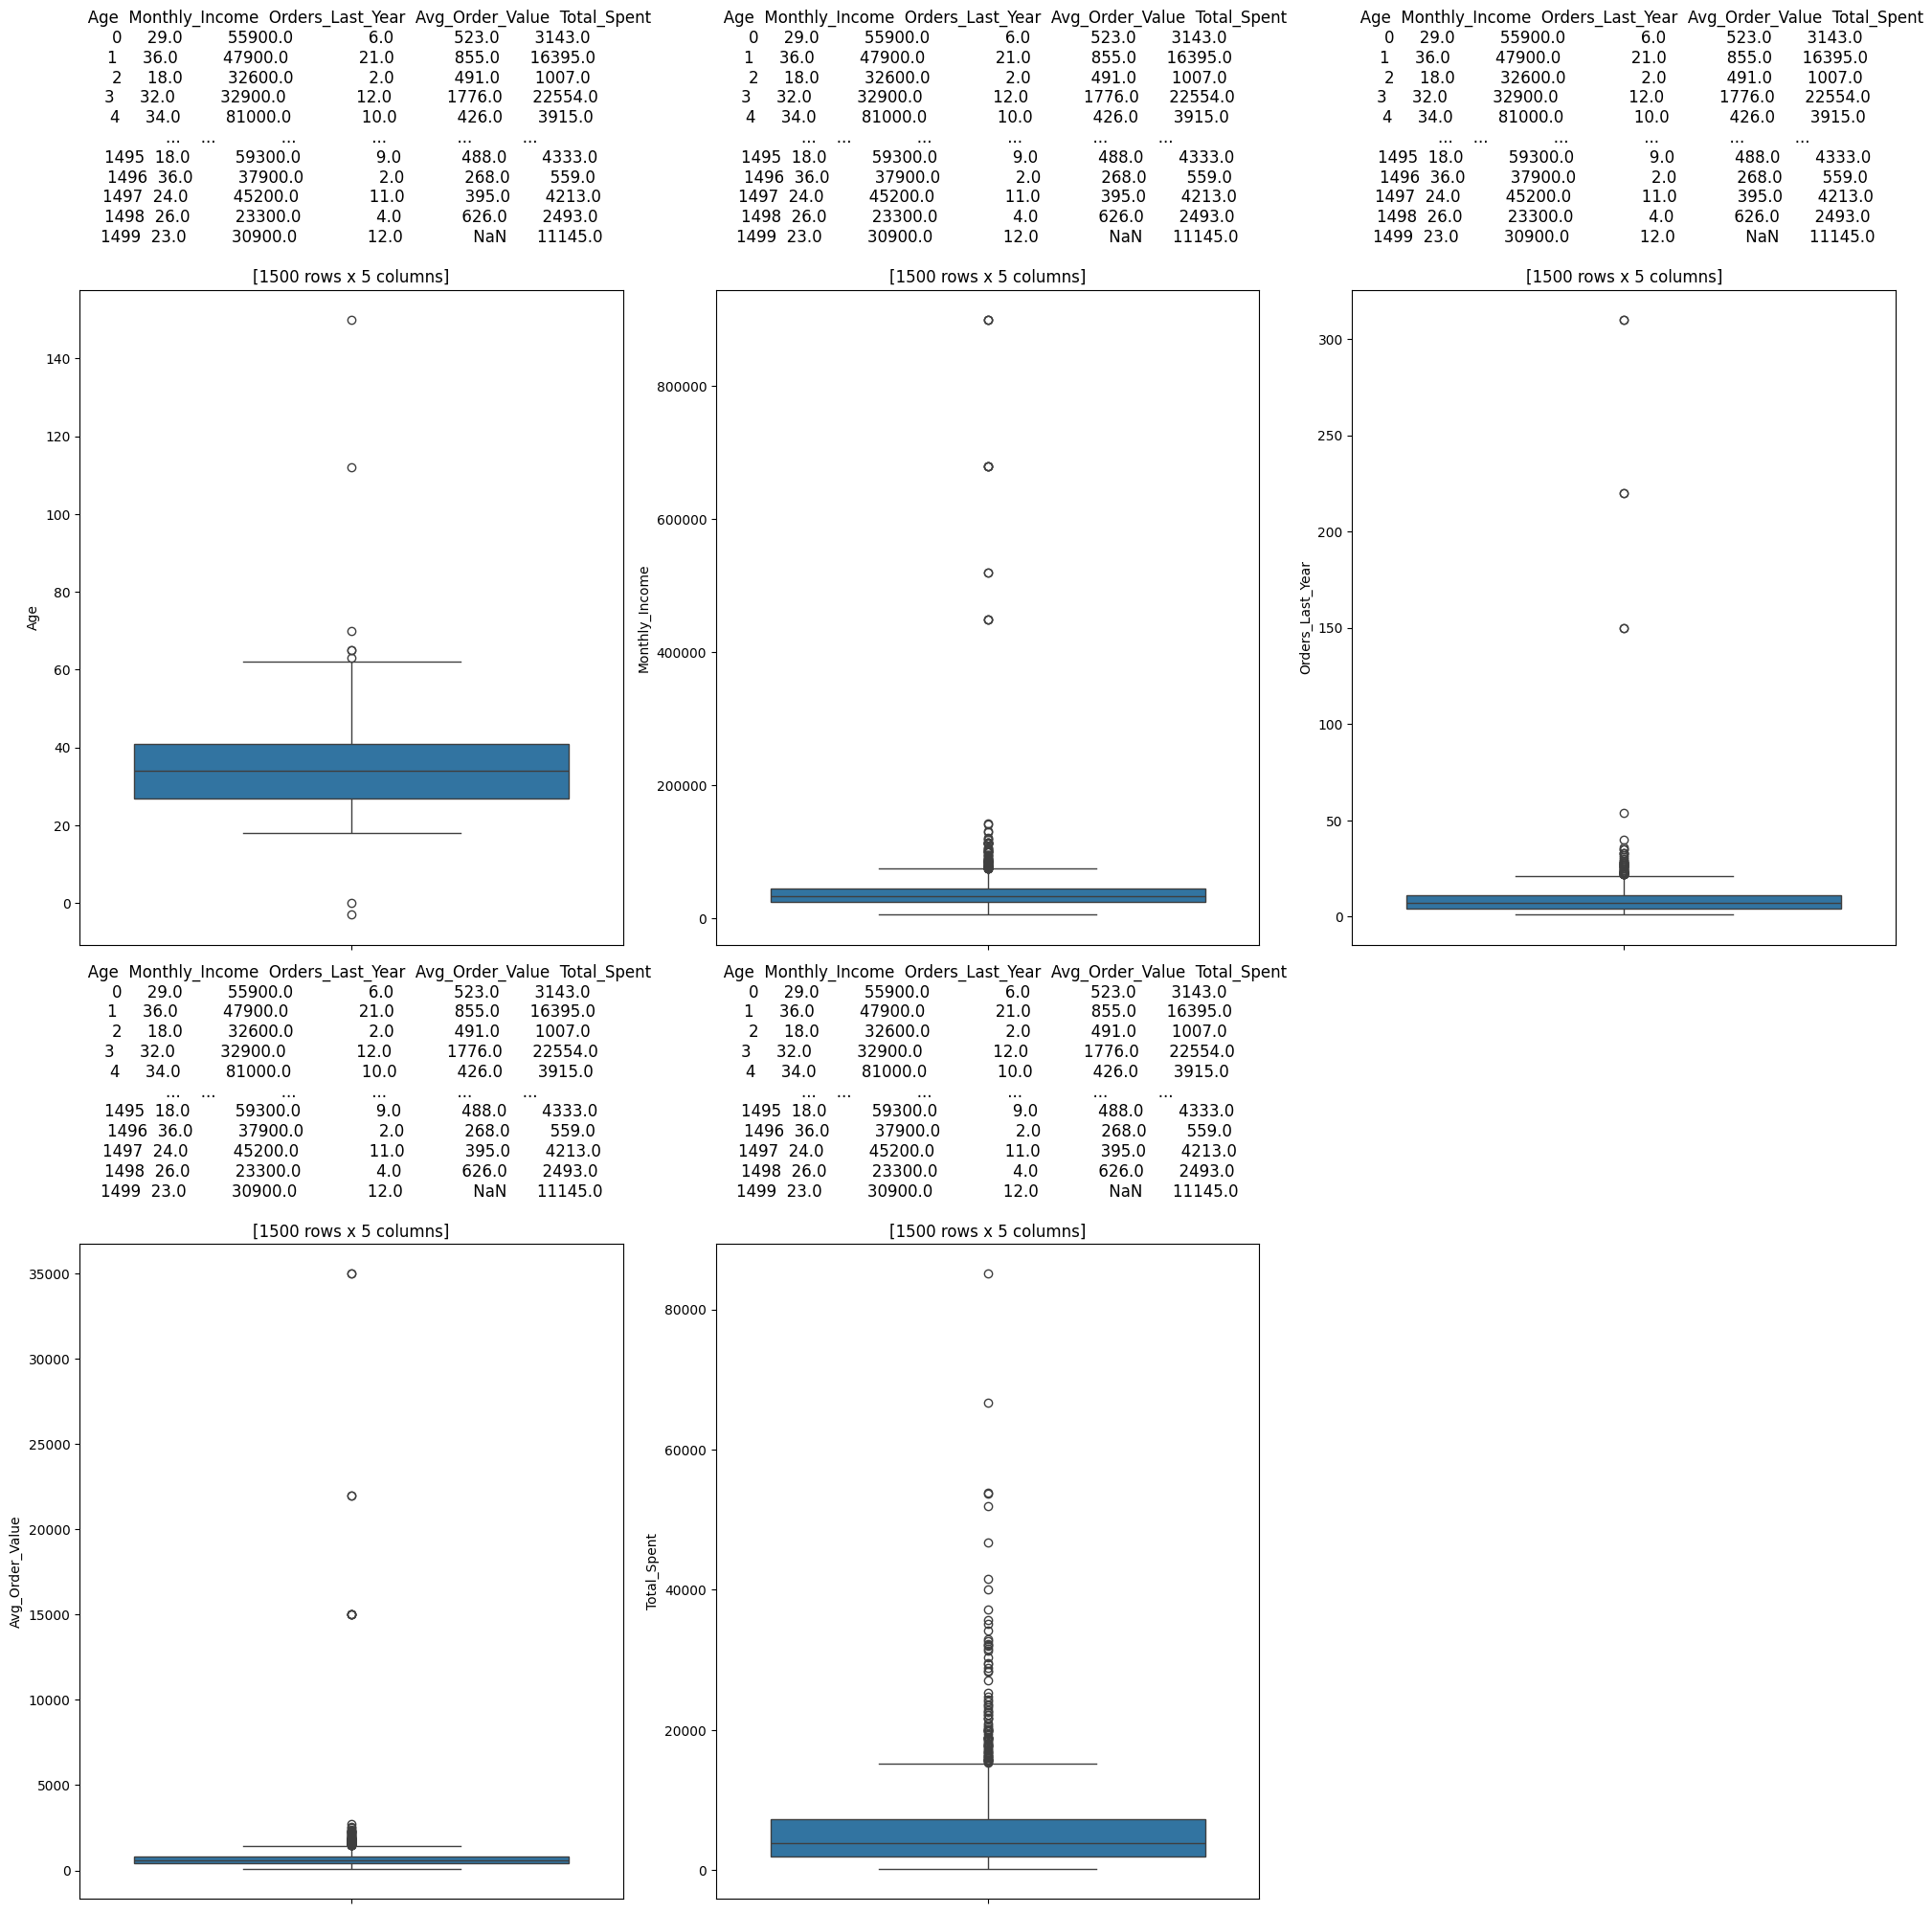

In [ ]:
plt.figure(figsize=(20, 30))
for i, spent in enumerate(num_Total_Spents,1):
  plt.subplot(3, 3, i)
  sns.boxplot(data=df[spent])
  plt.title(num_Total_Spents)

plt.tight_layout()
plt.show()

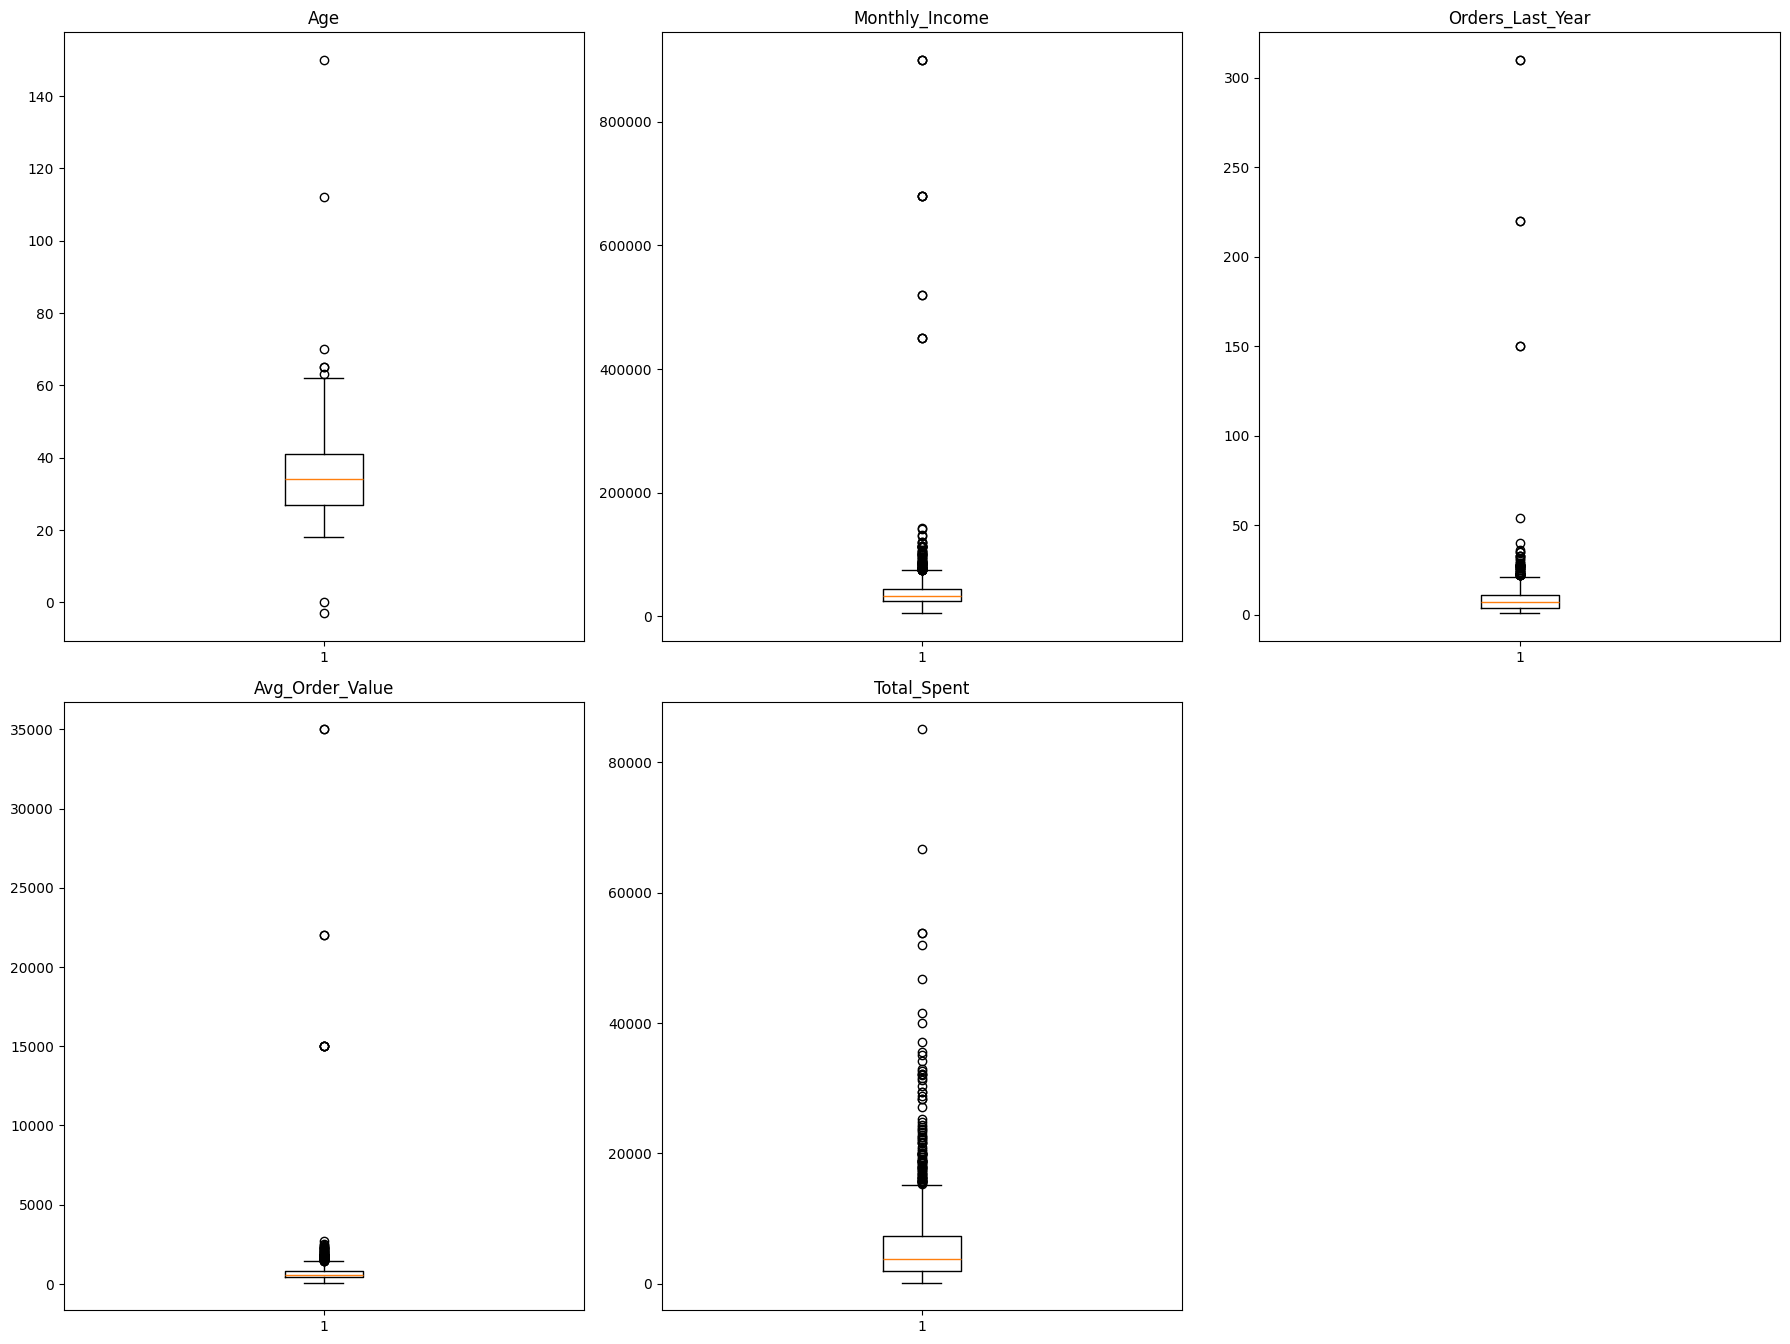

In [ ]:
plt.figure(figsize=(18, 20))
for i, spent in enumerate(num_Total_Spents, 1):
  plt.subplot(3, 3, i)
  plt.boxplot(df[spent] )
  plt.title(spent)



plt.tight_layout()
plt.show()

In [ ]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
City,0
Membership,0
Payment_Mode,0
Monthly_Income,0
Orders_Last_Year,0
Avg_Order_Value,0
Total_Spent,0


In [ ]:
df.shape


(1500, 10)

In [ ]:
Q1 = num_Total_Spents.quantile(0.25)
Q3 = num_Total_Spents.quantile(0.75)

IQR = Q3 - Q1

In [ ]:
df = pd.read_csv(filepath)
df.drop(columns=['Unnamed: 0'], axis=1, inplace=True, errors='ignore')

num_cols = ['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent']

for col in num_cols:
  df[col].fillna(df[col].median(), inplace=True)

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
upper_limit = Q3 + (1.5 * IQR)
lower_limit = Q1 - (1.5 * IQR)

df[num_cols] = df[num_cols].clip(lower=lower_limit, upper=upper_limit, axis=1)

display(df.head())

/tmp/ipykernel_826/2180182422.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].median(), inplace=True)


,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.000,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.000,15294.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.000,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1462.625,15294.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,74600.0,10.0,426.000,3915.0


In [ ]:
df.shape

(1465, 18)

In [ ]:
df_with_outliers

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.0,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.0,16395.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.0,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1776.0,22554.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,81000.0,10.0,426.0,3915.0
...,...,...,...,...,...,...,...,...,...,...
1495,C0057,18.0,Female,Kozhikode,Gold,UPI,59300.0,9.0,488.0,4333.0
1496,C0502,36.0,Female,Kozhikode,Basic,Cash on Delivery,37900.0,2.0,268.0,559.0
1497,C0639,24.0,Male,Kochi,Basic,UPI,45200.0,11.0,395.0,4213.0
1498,C0349,26.0,Female,Kochi,Basic,UPI,23300.0,4.0,626.0,2493.0


In [ ]:
Q1

,0.25
Age,27.00
Monthly_Income,25100.00
Orders_Last_Year,4.00
Avg_Order_Value,417.00
Total_Spent,1937.75


In [ ]:
Q3

,0.75
Age,41.00
Monthly_Income,44900.00
Orders_Last_Year,11.00
Avg_Order_Value,835.25
Total_Spent,7280.25


In [ ]:
IQR

,0
Age,14.00
Monthly_Income,19800.00
Orders_Last_Year,7.00
Avg_Order_Value,418.25
Total_Spent,5342.50


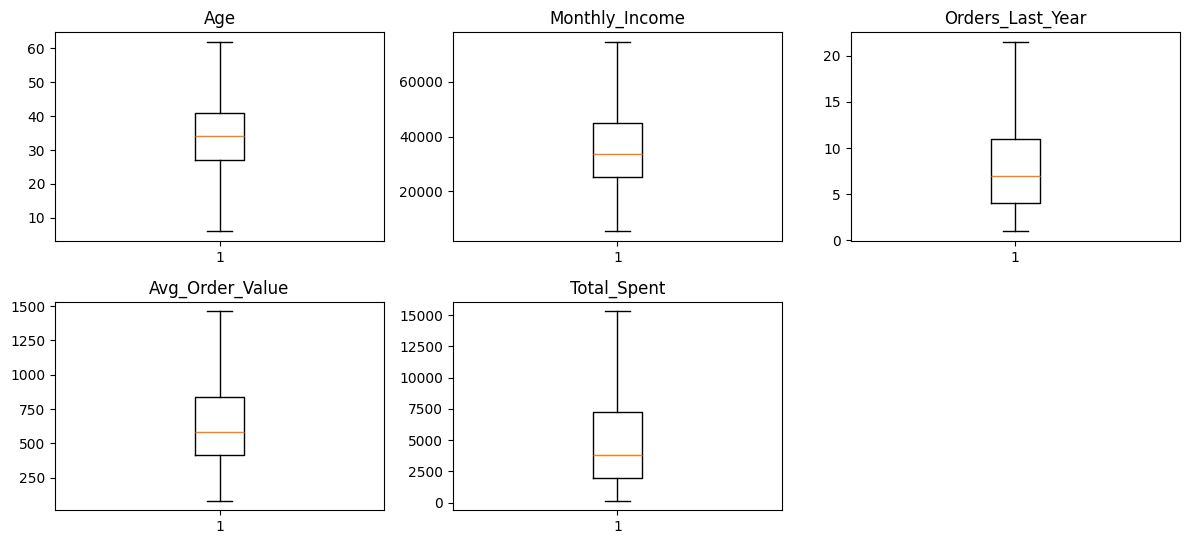

In [ ]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(num_Total_Spents, 1):
  plt.subplot(3, 3, i)
  plt.boxplot(df[col])
  plt.title(col)
  plt.tight_layout()

plt.show()

In [ ]:
df.duplicated().sum()

np.int64(35)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.head()

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,Kozhikode,Basic,Debit Card,55900.0,6.0,523.000,3143.0
1,C0758,36.0,Male,Thrissur,Silver,UPI,47900.0,21.0,855.000,15294.0
2,C0993,18.0,Male,Thrissur,Basic,UPI,32600.0,2.0,491.000,1007.0
3,C1171,32.0,Female,Kochi,Gold,Credit Card,32900.0,12.0,1462.625,15294.0
4,C1069,34.0,Female,Kochi,Gold,Cash on Delivery,74600.0,10.0,426.000,3915.0


In [ ]:
df['City'].value_counts()

,count
City,
Kochi,351
Trivandrum,224
Kozhikode,204
Thrissur,172
Kollam,139
Kannur,113
Alappuzha,112
Palakkad,71
kochi,3


In [ ]:
cat_Total_Spents

,Age,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,29.0,55900.0,6.0,523.0,3143.0
1,36.0,47900.0,21.0,855.0,16395.0
2,18.0,32600.0,2.0,491.0,1007.0
3,32.0,32900.0,12.0,1776.0,22554.0
4,34.0,81000.0,10.0,426.0,3915.0
...,...,...,...,...,...
1495,18.0,59300.0,9.0,488.0,4333.0
1496,36.0,37900.0,2.0,268.0,559.0
1497,24.0,45200.0,11.0,395.0,4213.0
1498,26.0,23300.0,4.0,626.0,2493.0


In [ ]:
df['City'].unique()

array(['Kozhikode', 'Thrissur', 'Kochi', 'Kollam', 'kochi', 'Palakkad',
       'Kannur', nan, 'Alappuzha', 'Trivandrum', 'Kochi ', 'Trivandrum ',
       'TRIVANDRUM', 'kozhikode', 'kollam', 'KOCHI', 'KOLLAM', 'thrissur'],
      dtype=object)

In [ ]:
df['City'] = df['City'].str.lower()

In [ ]:
label_encoder = LabelEncoder()
df['City'] = label_encoder.fit_transform(df['City'])

In [ ]:
df['City'].unique()

array([ 5,  7,  2,  4,  6,  1, 10,  0,  8,  3,  9])

In [ ]:
df.head(10)

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,5,Basic,Debit Card,55900.0,6.0,523.000,3143.0
1,C0758,36.0,Male,7,Silver,UPI,47900.0,21.0,855.000,15294.0
2,C0993,18.0,Male,7,Basic,UPI,32600.0,2.0,491.000,1007.0
3,C1171,32.0,Female,2,Gold,Credit Card,32900.0,12.0,1462.625,15294.0
4,C1069,34.0,Female,2,Gold,Cash on Delivery,74600.0,10.0,426.000,3915.0
5,C0800,24.0,Male,5,Gold,Credit Card,32100.0,14.0,480.000,6344.0
6,C1440,29.0,Male,4,Silver,Debit Card,38000.0,16.0,260.000,3890.0
7,C1422,42.0,Female,4,Gold,Debit Card,40900.0,18.0,1302.000,15294.0
8,C1200,18.0,Female,2,Silver,Cash on Delivery,66400.0,8.0,440.000,3643.0
9,C0516,43.0,Male,2,Basic,Debit Card,33300.0,8.0,482.000,3733.0


In [ ]:
df['Gender'].unique()

array(['Female', 'Male', 'Other', nan, 'F', 'M'], dtype=object)

In [ ]:
df['Gender'] = df['Gender'].replace({'F': 'Female', 'M': 'Male'})

In [ ]:
df['Gender'].unique()

array(['Female', 'Male', 'Other', nan], dtype=object)

In [ ]:
df.head(10)

,Customer_ID,Age,Gender,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent
0,C0258,29.0,Female,5,Basic,Debit Card,55900.0,6.0,523.000,3143.0
1,C0758,36.0,Male,7,Silver,UPI,47900.0,21.0,855.000,15294.0
2,C0993,18.0,Male,7,Basic,UPI,32600.0,2.0,491.000,1007.0
3,C1171,32.0,Female,2,Gold,Credit Card,32900.0,12.0,1462.625,15294.0
4,C1069,34.0,Female,2,Gold,Cash on Delivery,74600.0,10.0,426.000,3915.0
5,C0800,24.0,Male,5,Gold,Credit Card,32100.0,14.0,480.000,6344.0
6,C1440,29.0,Male,4,Silver,Debit Card,38000.0,16.0,260.000,3890.0
7,C1422,42.0,Female,4,Gold,Debit Card,40900.0,18.0,1302.000,15294.0
8,C1200,18.0,Female,2,Silver,Cash on Delivery,66400.0,8.0,440.000,3643.0
9,C0516,43.0,Male,2,Basic,Debit Card,33300.0,8.0,482.000,3733.0


In [ ]:
encoder = OneHotEncoder()
encoder_data = encoder.fit_transform(df[["Gender"]])

encoder_df = pd.DataFrame(
    encoder_data.toarray(),
    columns=encoder.get_feature_names_out(['Gender']),
    index=df.index
)
df = pd.concat([df, encoder_df], axis=1).drop(columns=['Gender'])

df.head()

,Customer_ID,Age,City,Membership,Payment_Mode,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Gender_nan
0,C0258,29.0,5,Basic,Debit Card,55900.0,6.0,523.000,3143.0,1.0,0.0,0.0,0.0
1,C0758,36.0,7,Silver,UPI,47900.0,21.0,855.000,15294.0,0.0,1.0,0.0,0.0
2,C0993,18.0,7,Basic,UPI,32600.0,2.0,491.000,1007.0,0.0,1.0,0.0,0.0
3,C1171,32.0,2,Gold,Credit Card,32900.0,12.0,1462.625,15294.0,1.0,0.0,0.0,0.0
4,C1069,34.0,2,Gold,Cash on Delivery,74600.0,10.0,426.000,3915.0,1.0,0.0,0.0,0.0


In [ ]:
encoder = OneHotEncoder()
encoder_data = encoder.fit_transform(df[["Payment_Mode"]])

encoder_df = pd.DataFrame(
    encoder_data.toarray(),
    columns=encoder.get_feature_names_out(['Payment_Mode']),
    index=df.index
)
df = pd.concat([df, encoder_df], axis=1).drop(columns=['Payment_Mode'])

df.head()

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Gender_nan,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI,Payment_Mode_nan
0,C0258,29.0,5,Basic,55900.0,6.0,523.000,3143.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,C0758,36.0,7,Silver,47900.0,21.0,855.000,15294.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,C0993,18.0,7,Basic,32600.0,2.0,491.000,1007.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,C1171,32.0,2,Gold,32900.0,12.0,1462.625,15294.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,C1069,34.0,2,Gold,74600.0,10.0,426.000,3915.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
print(df['Membership'].unique())

['Basic' 'Silver' 'Gold' 'SILVER' 'Platinum' 'PLATINUM' 'silver' 'GOLD'
 'basic']


In [ ]:
df['Membership'] = df['Membership'].str.lower()

In [ ]:
print(df['Membership'].unique())

['basic' 'silver' 'gold' 'platinum']


In [ ]:
encoder_health = OrdinalEncoder(
    categories=[['basic', 'silver', 'gold', 'platinum']]
)
df['Membership'] = encoder_health.fit_transform(df[['Membership']])

In [ ]:
df['Membership'].unique()

array([0., 1., 2., 3.])

In [ ]:
df.head(10)

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Gender_nan,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI,Payment_Mode_nan
0,C0258,29.0,5,0.0,55900.0,6.0,523.000,3143.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,C0758,36.0,7,1.0,47900.0,21.0,855.000,15294.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,C0993,18.0,7,0.0,32600.0,2.0,491.000,1007.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,C1171,32.0,2,2.0,32900.0,12.0,1462.625,15294.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,C1069,34.0,2,2.0,74600.0,10.0,426.000,3915.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5,C0800,24.0,5,2.0,32100.0,14.0,480.000,6344.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,C1440,29.0,4,1.0,38000.0,16.0,260.000,3890.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
7,C1422,42.0,4,2.0,40900.0,18.0,1302.000,15294.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
8,C1200,18.0,2,1.0,66400.0,8.0,440.000,3643.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,C0516,43.0,2,0.0,33300.0,8.0,482.000,3733.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:


num_cols_to_scale = ['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value','Total_Spent']

scaler = StandardScaler()

df[num_cols_to_scale] = scaler.fit_transform(df[num_cols_to_scale])

display(df.head(10))

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Gender_nan,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI,Payment_Mode_nan
0,C0258,-0.537494,5,0.0,1.187149,-0.370555,-0.415223,-0.479371,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,C0758,0.193541,7,1.0,0.689702,2.457345,0.572356,2.432144,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,C0993,-1.686262,7,0.0,-0.261665,-1.124661,-0.510411,-0.991180,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,C1171,-0.224193,2,2.0,-0.243010,0.760605,2.379819,2.432144,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,C1069,-0.015326,2,2.0,2.349932,0.383552,-0.703762,-0.294391,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5,C0800,-1.059661,5,2.0,-0.292755,1.137658,-0.543132,0.287624,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,C1440,-0.537494,4,1.0,0.074112,1.514712,-1.197552,-0.300381,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
7,C1422,0.820141,4,2.0,0.254436,1.891765,1.902018,2.432144,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
8,C1200,-1.686262,2,1.0,1.840048,0.006499,-0.662118,-0.359565,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,C0516,0.924575,2,0.0,-0.218138,0.006499,-0.537183,-0.338000,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


In [ ]:


num_cols_to_scale = ['Age', 'Monthly_Income', 'Orders_Last_Year', 'Avg_Order_Value', 'Total_Spent']


min_max_scaler = MinMaxScaler()


df[num_cols_to_scale] = min_max_scaler.fit_transform(df[num_cols_to_scale])


display(df.head(10))

,Customer_ID,Age,City,Membership,Monthly_Income,Orders_Last_Year,Avg_Order_Value,Total_Spent,Gender_Female,Gender_Male,Gender_Other,Gender_nan,Payment_Mode_Cash on Delivery,Payment_Mode_Credit Card,Payment_Mode_Debit Card,Payment_Mode_Net Banking,Payment_Mode_UPI,Payment_Mode_nan
0,C0258,0.410714,5,0.0,0.729378,0.243902,0.319913,0.197265,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
1,C0758,0.535714,7,1.0,0.613603,0.975610,0.560210,1.000000,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,C0993,0.214286,7,0.0,0.392185,0.048780,0.296752,0.056154,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,C1171,0.464286,2,2.0,0.396527,0.536585,1.000000,1.000000,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,C1069,0.500000,2,2.0,1.000000,0.439024,0.249706,0.248266,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
5,C0800,0.321429,5,2.0,0.384949,0.634146,0.288790,0.408734,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
6,C1440,0.410714,4,1.0,0.470333,0.731707,0.129558,0.246614,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
7,C1422,0.642857,4,2.0,0.512301,0.829268,0.883742,1.000000,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
8,C1200,0.214286,2,1.0,0.881331,0.341463,0.259839,0.230297,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9,C0516,0.660714,2,0.0,0.402315,0.341463,0.290238,0.236242,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
